# GOBRec Tutorial: Optimized Bandits and Recommender Evaluation

GOBRec (GPU Optimized Bandits Recommender) is a Python library that implements computationally optimized contextual multi-armed bandit (CMAB) methods for recommendation. Its implementations use vectorized tensor operations and support optional GPU acceleration to make training and inference more efficient, especially as the number of interactions and candidate items grows. The library includes linear methods such as LinUCB, LinTS, and LinGreedy, as well as a Random baseline. A central design goal is to keep contextual representations independent from the bandit algorithm, so researchers can provide their own context features and experiment with different policies.

GOBRec has two main components: **MAB algorithms**, which learn from context–item–reward interactions and estimate expected rewards for candidate items, and a **Recommender** class, which uses a MAB algorithm to rank items and return top-*K* recommendations. GOBRec intentionally does **not** aim to provide every component required by a complete recommender-system (RecSys) workflow. Its primary purpose is the optimized implementation of bandit algorithms and the recommender logic that uses them. A full system can combine GOBRec with complementary tools, for example: **Selective, TextWise, and Seq2Pat** for feature extraction; **mab2rec** for recsys training/evaluation pipelines; and **Jurity** for recommendation metrics. The precise role of each tool depends on the dataset and workflow.

This tutorial has two parts:

1. **Using GOBRec directly:** understand the MAB and Recommender APIs, input and output data structures, item filtering, and how to enable or disable GPU execution.
2. **Integrating into a RecSys workflow:** use a MovieLens 100K example inspired by [mab2rec's evaluation notebook](https://github.com/fidelity/mab2rec/blob/main/notebooks/4_evaluation.ipynb). Using a wrapper class, we coupled GOBRec recommenders into the mab2rec benchmark code.

## 0. Install dependencies

Run this cell in an environment where you can install packages. For GPU support, install a CUDA-enabled PyTorch build appropriate for your machine **before** installing GOBRec. A CPU-only PyTorch installation is fine if you set `USE_GPU = False`.

In [1]:
%pip install -U gobrec mab2rec jurity pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Part 1 — Use GOBRec directly

## 1.1. Imports and GPU availability

`use_gpu=True` requests GPU execution for the supported GOBRec algorithm. It does not install CUDA or a GPU driver. The environment must have a compatible CUDA-enabled PyTorch installation and a working GPU runtime. Use `False` to force CPU execution.

In [2]:
import numpy as np
import torch
import gobrec
from gobrec.mabs.lin_mabs import Lin, LinUCB, LinTS, LinGreedy

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# Change to False to force CPU execution.
USE_GPU = torch.cuda.is_available()
print("GOBRec use_gpu =", USE_GPU)

PyTorch: 2.4.1+cu121
CUDA available: True
GOBRec use_gpu = True


## 1.2. The MAB API: fit and predict

The standard training inputs are aligned arrays:

- `contexts`: 2-D array with shape `(n_interactions, n_features)`. Each row describes the context for one observed interaction.
- `decisions`: 1-D array with shape `(n_interactions,)`. Each value is the item/arm selected for that interaction. Item IDs can be strings or integers; using one consistent ID type is recommended.
- `rewards`: 1-D array with shape `(n_interactions,)`. Each value is the observed reward (for example, a rating or implicit feedback signal).

`fit(contexts, decisions, rewards)` updates the bandit from these observations. `predict(contexts)` returns a PyTorch tensor of expected rewards with shape `(n_contexts, n_arms)`. The columns correspond to the algorithm's encoded item IDs; use `bandit.label_encoder.inverse_transform(...)` to map encoded arm indices back to original IDs.

In [3]:
# A tiny illustrative interaction log.

# Below, we have a simple interaction log with two contexts (user features) and three decisions (items). The rewards are the ratings given by the users to the items.
# Basicaly, we have two users (contexts) and three movies (decisions). The first user likes movie_A the most, dislikes movie_B, and is neutral about movie_C. The second user likes movie_B the most, dislikes movie_A, and is neutral about movie_C.
contexts = np.array([
    [1.0, 0.0], [1.0, 0.0], [1.0, 0.0],
    [0.0, 1.0], [0.0, 1.0], [0.0, 1.0],
])
decisions = np.array([
    "movie_A", "movie_B", "movie_C",
    "movie_A", "movie_B", "movie_C"
])
rewards = np.array([
    5.0, 1.0, 3.0, 
    1.0, 5.0, 3.0
])


# Instanciate a LinUCB bandit and fit it to the interaction log. The bandit will learn the expected rewards for each decision given the contexts.
bandit = gobrec.mabs.lin_mabs.LinUCB(seed=42, use_gpu=USE_GPU)
bandit.fit(contexts, decisions, rewards)

# Contexts for which we want to predict the expected rewards for each decision. The first context is similar to the first user, and the second context is similar to the second user.
new_contexts = np.array([
    [0.9, 0.1],  # Is similar to the first user, so it should prefer movie_A and dislike movie_B.
    [0.1, 0.9],  # Is similar to the second user, so it should prefer movie_B and dislike movie_A.
])
expected_rewards = bandit.predict(new_contexts)

print("Output type:", type(expected_rewards))
print("Expected-reward tensor shape:", tuple(expected_rewards.shape))
print("Known item IDs:", bandit.label_encoder.classes_)
print("Expected rewards:", expected_rewards)

Output type: <class 'torch.Tensor'>
Expected-reward tensor shape: (2, 3)
Known item IDs: ['movie_A' 'movie_B' 'movie_C']
Expected rewards: tensor([[2.9403, 1.3403, 2.1403],
        [1.3403, 2.9403, 2.1403]], device='cuda:0', dtype=torch.float64)


## 1.3. The Recommender API: top-*K* items

`gobrec.Recommender(mab_algo=..., top_k=...)` wraps a MAB implementation. Its `fit` method accepts the same three arrays. Its `recommend(contexts)` method returns a pair:

1. `recommendations`: NumPy array with shape `(n_contexts, top_k)`, containing original item IDs.
2. `scores`: NumPy array with shape `(n_contexts, top_k)`, containing the corresponding predicted scores in recommendation order.

To filter items recommendations, for example, filtering recommending items a user has already consumed, pass `decisions_filter=[context_indices, item_ids]`. Each entry pairs a row index in the context batch with an item ID to exclude. Only items known to the fitted bandit can be filtered this way.

In [4]:

# Now, let's use the `Recommender` class to get the top-k recommendations for the new contexts. The `Recommender` class wraps around a bandit algorithm and provides a convenient interface for making recommendations.
recommender = gobrec.Recommender(
    mab_algo=gobrec.mabs.lin_mabs.LinUCB(seed=42, use_gpu=USE_GPU),
    top_k=2,
)
recommender.fit(contexts, decisions, rewards)
recommendations, recommendation_scores = recommender.recommend(new_contexts)


print("Recommendations shape:", recommendations.shape)
print("Scores shape:", recommendation_scores.shape)
print("Recommendations:\n", recommendations)
print("Scores:\n", recommendation_scores)

# You can also filter the recommendations using the `decisions_filter` argument. In the example below, we are removing "movie_A" from the first context's recommendations and "movie_B" from the second context's recommendations.
filtered_recommendations, filtered_scores = recommender.recommend(
    new_contexts,
    decisions_filter=[np.array([0, 1]), np.array(["movie_A", "movie_B"])],
)
print("Filtered recommendations:\n", filtered_recommendations)

Recommendations shape: (2, 2)
Scores shape: (2, 2)
Recommendations:
 [['movie_A' 'movie_C']
 ['movie_B' 'movie_C']]
Scores:
 [[2.94031242 2.14031242]
 [2.94031242 2.14031242]]
Filtered recommendations:
 [['movie_C' 'movie_B']
 ['movie_C' 'movie_A']]


## 1.4. Further Documentation and Resources

For more detailed information about GOBRec, including its API, available algorithms, installation instructions, and usage examples, refer to the [official documentation](https://ufscar-lasid.github.io/gobrec/index.html).

The repository also provides additional resources to help you understand, reproduce, and extend the library:

- **[`/experiments`](https://github.com/UFSCar-LaSID/gobrec/tree/main/experiments):** Contains the code used to benchmark GOBRec against other recommender-system libraries, including mab2rec and iRec. These experiments provide further insight into the library's computational efficiency and scalability, as well as instructions for reproducing the reported results.
- **[`/tests`](https://github.com/UFSCar-LaSID/gobrec/tree/main/tests):** Contains the automated test suite used to verify the library's behavior. Exploring these tests can help you understand the expected inputs and outputs of its methods, validate its functionalities, and better understand how its components are expected to work.

Together, these resources complement this tutorial by providing more comprehensive API documentation, reproducible performance evaluations, and executable examples of the library's expected behavior.

# Part 2 — A complete evaluation workflow with GOBRec, mab2rec, and Jurity

This section follows the broad structure of [mab2rec's evaluation notebook](https://github.com/fidelity/mab2rec/blob/main/notebooks/4_evaluation.ipynb): load interaction data, define recommenders and metrics, run training/inference, and compare results.

## 2.1 Initial configurations and imports

In [5]:
import os
import shutil
os.chdir('..')

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import seaborn as sns

sns.set_context("notebook", font_scale=1.4)
cmap = sns.diverging_palette(220, 10, as_cmap=True)

tmp_dir = "tmp_dir"
os.makedirs(tmp_dir, exist_ok=True)

## 2.2. Load MovieLens train and eval data

This section downloads the prepared MovieLens 100K files used by mab2rec's evaluation example. `data_train.csv` contains the interactions used to fit each recommender, while `data_test.csv` contains held-out interactions for evaluation. The two feature files provide user and item features for the workflow. The next cells download these files into `data/` and load them into pandas DataFrames. If the files are already available locally, you can skip the download cell and update the paths as needed.

In [6]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

base_url = (
    "https://raw.githubusercontent.com/"
    "fidelity/mab2rec/main/data/"
)

files = [
    "data_train.csv",
    "data_test.csv",
    "features_user.csv",
    "features_item.csv",
]

for filename in files:
    urlretrieve(base_url + filename, data_dir / filename)

In [7]:
# Input data
train_data = "data/data_train.csv"
test_data = "data/data_test.csv"

user_features = "data/features_user.csv"
item_features = "data/features_item.csv"

# Read data
train_df = pd.read_csv(train_data)
test_df = pd.read_csv(test_data)

user_features_df = pd.read_csv(user_features)
item_features_df = pd.read_csv(item_features)

## 2.3. Instantiate recommenders

We compare two contextual bandit policies provided by mab2rec (LinGreedy and LinUCB) with corresponding GOBRec implementations. Each recommender is configured to return up to 10 items and uses a fixed seed for reproducibility. `Mab2recWrapper` adapts GOBRec's `Recommender` to the interface expected by this example's mab2rec pipeline. It is a lightweight example adapter, not a general-purpose integration. Treat comparisons involving this wrapper accordingly, and validate or extend the adapter before using it for a production evaluation.

In [8]:
from mab2rec import BanditRecommender
from types import SimpleNamespace


class Mab2recWrapper(BanditRecommender):
    def __init__(self, gobrec_recommender):
        self.gobrec_recommender = gobrec_recommender
        self.mab = SimpleNamespace(is_contextual=True, _is_initial_fit=False)
    
    def fit(self, decisions, rewards, contexts):
        self.gobrec_recommender.fit(contexts.to_numpy(), decisions.to_numpy(), rewards.to_numpy())
        self.mab._is_initial_fit = True

    def recommend(self, contexts, excluded_arms, return_scores=True, apply_sigmoid=True):
        recs, scores = self.gobrec_recommender.recommend(contexts.to_numpy())
        return recs.tolist(), scores.tolist()
    
    def set_arms(self, arms):
        pass

In [9]:
from mab2rec import BanditRecommender, LearningPolicy, NeighborhoodPolicy

# Set of recommenders
recommenders = {
      "mab2rec - LinGreedy": BanditRecommender(
            learning_policy=LearningPolicy.LinGreedy(epsilon=0.01), seed=42, top_k=10
      ),
      "mab2rec - LinUCB": BanditRecommender(
            learning_policy=LearningPolicy.LinUCB(alpha=0.1), seed=42, top_k=10
      ),

      'gobrec - LinGreedy': Mab2recWrapper(gobrec.Recommender(
            mab_algo=gobrec.mabs.lin_mabs.LinGreedy(epsilon=0.01, seed=42, use_gpu=USE_GPU), top_k=10,
      )),
      'gobrec - LinUCB': Mab2recWrapper(gobrec.Recommender(
            mab_algo=gobrec.mabs.lin_mabs.LinUCB(alpha=0.1, seed=42, use_gpu=USE_GPU), top_k=10,
      ))
}


## 2.4. Define Jurity metrics

Jurity provides the evaluation metrics used to assess the quality of ranked recommendations. Following the mab2rec tutorial, we use six metrics: `AUC`, `CTR`, `Precision`, `Recall`, `NDCG`, and `MAP`. Each metric captures a different aspect of recommendation performance. For detailed explanations of these metrics and their usage, refer to the [official Jurity documentation](https://fidelity.github.io/jurity/about_reco.html#).

In [10]:
from jurity.recommenders import BinaryRecoMetrics, RankingRecoMetrics

# Column names for the response, user, and item id columns
metric_params = {'click_column': 'score', 'user_id_column': 'user_id', 'item_id_column':'item_id'}

# Evaluate peformance at different k-recommendations
top_k_list = [3, 5, 10]

# List of metrics to benchmark
metrics = []
for k in top_k_list:
    metrics.append(BinaryRecoMetrics.AUC(**metric_params, k=k))
    metrics.append(BinaryRecoMetrics.CTR(**metric_params, k=k))
    metrics.append(RankingRecoMetrics.Precision(**metric_params,  k=k))
    metrics.append(RankingRecoMetrics.Recall(**metric_params, k=k))
    metrics.append(RankingRecoMetrics.NDCG(**metric_params, k=k))
    metrics.append(RankingRecoMetrics.MAP(**metric_params, k=k))
    
metrics

## 2.5. Run mab2rec's benchmark pipeline

The `benchmark` function runs the configured recommenders using the training interactions and evaluates their recommendations against the held-out test interactions. It also receives the user-feature file so the pipeline can supply context to contextual recommenders. The function returns `reco_to_results` and `reco_to_metrics`, which contain the benchmark outputs and metric results used in the following visualization.

In [11]:
from mab2rec.pipeline import benchmark

# Benchmark the set of recommenders for the list of metrics 
# using training data and user features scored on test data 
reco_to_results, reco_to_metrics = benchmark(recommenders, 
                                             metrics=metrics,
                                             train_data=train_data, 
                                             test_data=test_data,
                                             user_features=user_features)

## 2.6. Visualize the results

Finally, `plot_metrics_at_k` summarizes the metric values for the different recommenders and recommendation cutoffs. The plots make it easier to compare how each policy performs across metrics and K values.

**Note:** The mab2rec and GOBRec implementations achieve very similar results. As a result, their plot lines overlap, making it appear that each plot contains only two lines instead of four.

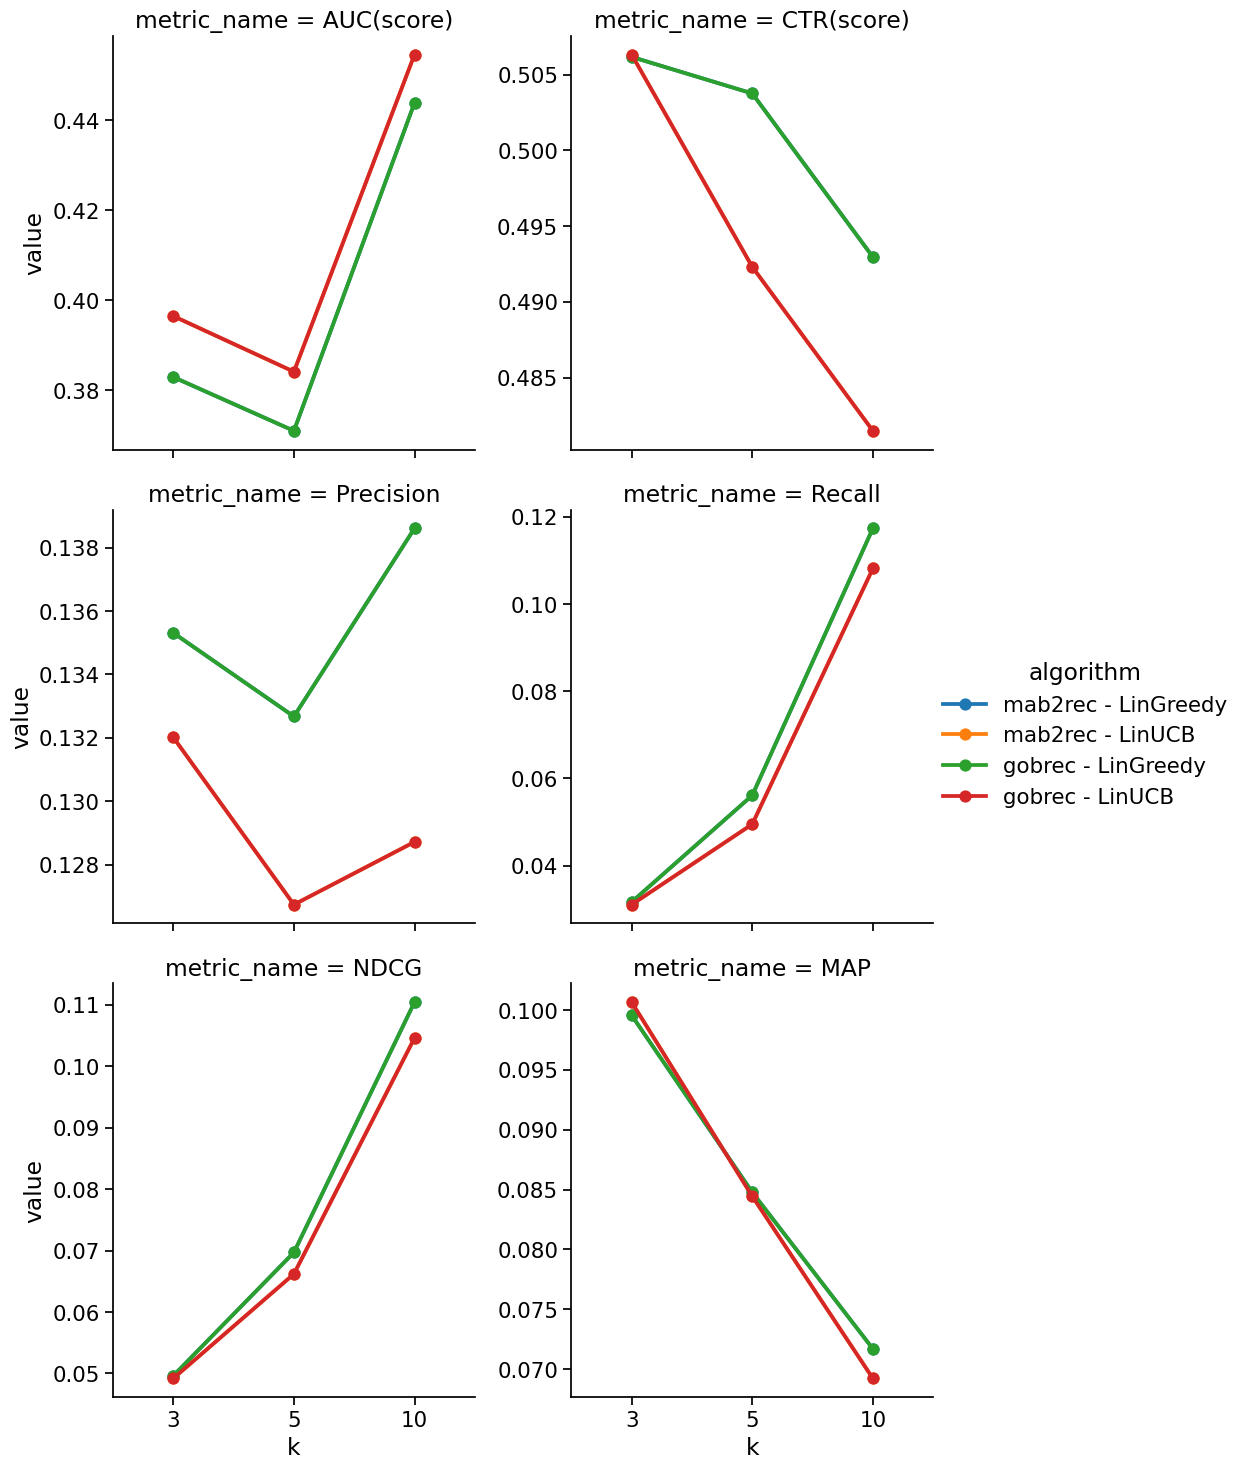

In [13]:
from mab2rec.visualization import plot_metrics_at_k

# Plot each metric across all algorithms at different k
plot_metrics_at_k(reco_to_metrics, col_wrap=2)

## Practical notes

- **Context design matters.** GOBRec consumes numeric context vectors; feature extraction and representation learning are intentionally outside its core scope.
- **Reward design matters.** This example uses explicit ratings to train the bandit, but binary relevance to evaluate ranking. Change this deliberately for your application.
- **Previously consumed items.** Exclude training items when recommending. Check that the requested `top_k` is feasible after filtering.
- **Memory.** GOBRec's vectorized operations can improve throughput but may require additional memory. Adjust the batch size based on your hardware limitations.
- **Native pipeline vs. adapter.** mab2rec handles its own recommender abstractions and pipeline. To make GOBRec a first-class mab2rec component, implement and test an adapter that satisfies the exact interface required by your installed mab2rec version; do not assume the APIs are interchangeable.

## References

- [GOBRec repository](https://github.com/UFSCar-LaSID/gobrec)
- [mab2rec evaluation notebook](https://github.com/fidelity/mab2rec/blob/main/notebooks/4_evaluation.ipynb)
- [mab2rec repository](https://github.com/fidelity/mab2rec)
- [Jurity repository](https://github.com/fidelity/jurity)
- [Jurity recommender metrics documentation](https://fidelity.github.io/jurity/about_reco.html)